# Experiment 1: Text Data Preprocessing

**Course:** Multimodal Data Analysis (BAI-417)  
**Name:** Sneha Roychowdhury  
**Section:** ECE-AI (2)

**Objective:** To preprocess and vectorize textual data for machine learning models.

Pipeline: cleaning → tokenisation → stopword removal → lemmatisation → Bag-of-Words and TF-IDF vectors.
Part A runs every step on the single review in `reviews_1_entry.csv`; Part B builds a vocabulary across the five reviews in `reviews_5_entries.csv`.

## Setup
spaCy and its small English model come preinstalled on Colab.

In [1]:
import re
import pandas as pd
import spacy
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

nlp = spacy.load("en_core_web_sm")

## Preprocessing function

In [2]:
def preprocess(text, verbose=False):
    cleaned = re.sub(r"[^a-z\s]", " ", text.lower())   # lowercase, no punctuation
    cleaned = re.sub(r"\s+", " ", cleaned).strip()
    doc = nlp(cleaned)
    tokens = [t.text for t in doc]                     # tokenisation
    no_stop = [t for t in doc if not t.is_stop]        # stopword removal
    lemmas = [t.lemma_ for t in no_stop]               # lemmatisation
    if verbose:
        print("Original    :", text)
        print("Cleaned     :", cleaned)
        print("Tokens      :", tokens)
        print("No stopwords:", [t.text for t in no_stop])
        print("Lemmatised  :", lemmas, "\n")
    return " ".join(lemmas)

## Part A: single review

In [3]:
# ---------- Part A: single review (reviews_1_entry.csv) ----------
df1 = pd.read_csv("reviews_1_entry.csv")
print("reviews_1_entry.csv:", df1.shape)
processed = preprocess(df1.loc[0, "ReviewText"], verbose=True)

tfidf_1 = TfidfVectorizer()
X1 = tfidf_1.fit_transform([processed])
print("Vocabulary  :", list(tfidf_1.get_feature_names_out()))
print("TF-IDF shape:", X1.shape)
print("TF-IDF row  :", X1.toarray().round(4), "\n")

reviews_1_entry.csv: (1, 2)
Original    : The product quality is excellent, and the service is outstanding.
Cleaned     : the product quality is excellent and the service is outstanding
Tokens      : ['the', 'product', 'quality', 'is', 'excellent', 'and', 'the', 'service', 'is', 'outstanding']
No stopwords: ['product', 'quality', 'excellent', 'service', 'outstanding']
Lemmatised  : ['product', 'quality', 'excellent', 'service', 'outstanding'] 

Vocabulary  : ['excellent', 'outstanding', 'product', 'quality', 'service']
TF-IDF shape: (1, 5)
TF-IDF row  : [[0.4472 0.4472 0.4472 0.4472 0.4472]] 



## Part B: five reviews

In [4]:
# ---------- Part B: five reviews (reviews_5_entries) ----------
df = pd.read_csv("reviews_5_entries.csv")       # same data as reviews_5_entries.pdf
print("reviews_5_entries:", df.shape)
df["Processed"] = df["ReviewText"].apply(preprocess)
print(df[["ReviewID", "Processed"]].to_string(index=False), "\n")

bow = CountVectorizer()
X_bow = bow.fit_transform(df["Processed"])
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(df["Processed"])
vocab = tfidf.get_feature_names_out()

print("Vocabulary size:", len(vocab))
print("Vocabulary     :", list(vocab), "\n")
print("BoW matrix shape   :", X_bow.shape)
print("TF-IDF matrix shape:", X_tfidf.shape, "\n")

tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=vocab,
                        index=[f"R{i}" for i in df.ReviewID])
print("TF-IDF vector of review 1 (non-zero terms):")
print(tfidf_df.loc["R1"][tfidf_df.loc["R1"] > 0].round(4).to_string(), "\n")

for rid, row in tfidf_df.iterrows():
    top = row.sort_values(ascending=False).head(3)
    print(f"{rid} top terms:", ", ".join(f"{w} ({v:.2f})" for w, v in top.items()))

reviews_5_entries: (5, 2)
 ReviewID                                           Processed
        1       product quality excellent service outstanding
        2                     delivery quick packaging secure
        3                      product work instruction clear
        4 customer support resolve issue politely efficiently
        5   item arrive late overall experience disappointing 

Vocabulary size: 24
Vocabulary     : ['arrive', 'clear', 'customer', 'delivery', 'disappointing', 'efficiently', 'excellent', 'experience', 'instruction', 'issue', 'item', 'late', 'outstanding', 'overall', 'packaging', 'politely', 'product', 'quality', 'quick', 'resolve', 'secure', 'service', 'support', 'work'] 

BoW matrix shape   : (5, 24)
TF-IDF matrix shape: (5, 24) 

TF-IDF vector of review 1 (non-zero terms):
excellent      0.4637
outstanding    0.4637
product        0.3741
quality        0.4637
service        0.4637 

R1 top terms: excellent (0.46), service (0.46), quality (0.46)
R2 top

## TF-IDF heatmap

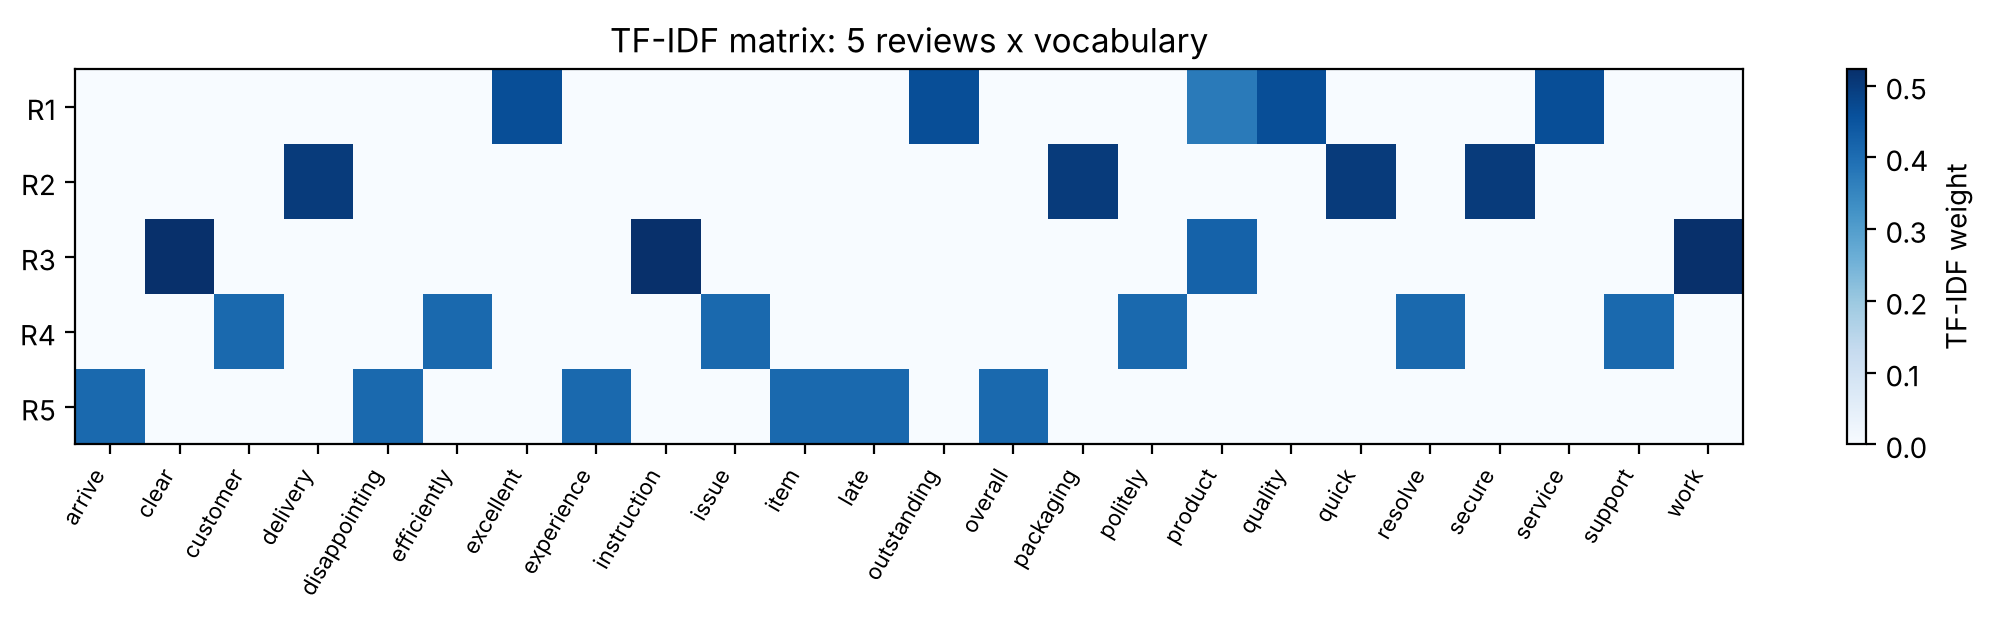

In [5]:
# Heatmap of the TF-IDF matrix
plt.figure(figsize=(11, 3.2))
plt.imshow(tfidf_df.values, cmap="Blues", aspect="auto")
plt.colorbar(label="TF-IDF weight")
plt.xticks(range(len(vocab)), vocab, rotation=60, ha="right", fontsize=8)
plt.yticks(range(len(tfidf_df)), tfidf_df.index)
plt.title("TF-IDF matrix: 5 reviews x vocabulary")
plt.tight_layout()
plt.savefig("exp1_tfidf_heatmap.png", dpi=200)
plt.show()